[Cell 1 Complete] Output directory: ./output_video_diffusion | Device: cuda
[Cell 2 Complete] MovingShapesDataset defined successfully.
[Cell 3 Complete] DiffusionScheduler defined successfully.
[Cell 4 Complete] SmallVideoDenoiser architecture built successfully.
[Cell 5 Complete] sample_video function defined successfully.
[Cell 6 Complete] Visualization and export helpers defined.
[Cell 7 Complete] train_model pipeline defined.
[Cell 7b Complete] Flow Matching pipeline defined successfully.

--- Starting Training Run: LINEAR Schedule ---
[Linear] Epoch 05/15 | Train Loss: 0.05550 | Val Loss: 0.05092
[Linear] Epoch 10/15 | Train Loss: 0.04128 | Val Loss: 0.03763
[Linear] Epoch 15/15 | Train Loss: 0.02825 | Val Loss: 0.02416
[Saved Checkpoint] ./output_video_diffusion/checkpoint_linear.pt

--- Starting Training Run: COSINE Schedule ---
[Cosine] Epoch 05/15 | Train Loss: 0.05311 | Val Loss: 0.04968
[Cosine] Epoch 10/15 | Train Loss: 0.03702 | Val Loss: 0.03032
[Cosine] Epoch 15/15 | Tr

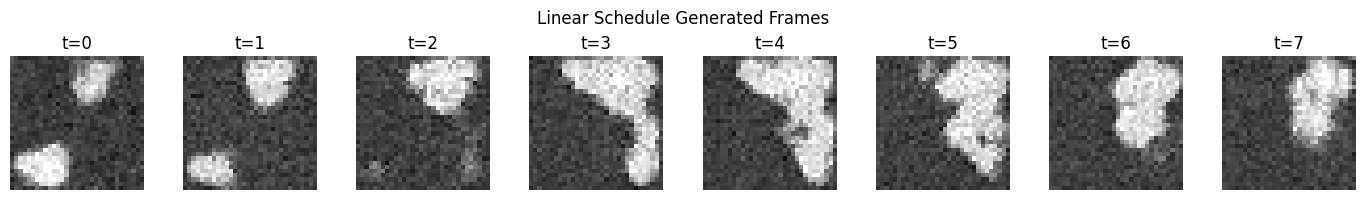

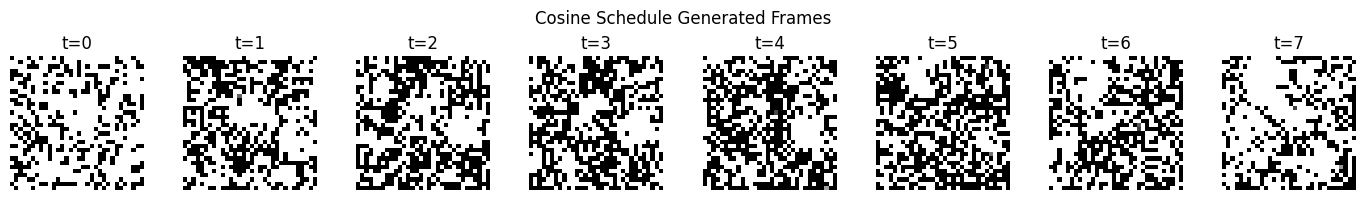

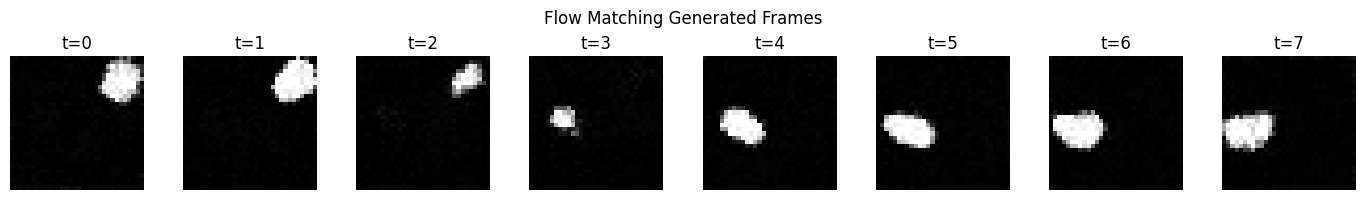

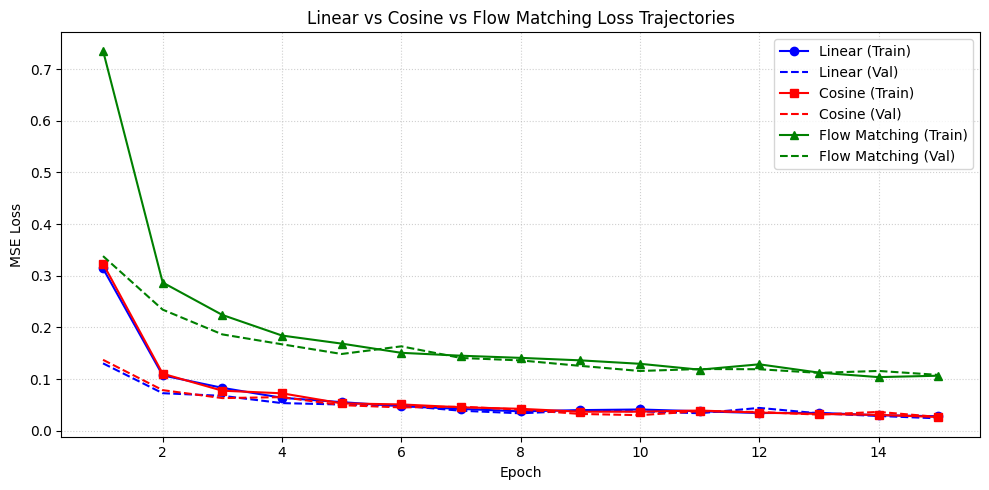


EXPERIMENT COMPARISON RESULTS
Linear Schedule Final Validation Loss:        0.02416
Cosine Schedule Final Validation Loss:        0.02680
Flow Matching Final Validation Loss:          0.10823

COMPRESSING AND EXPORTING GENERATED VIDEOS
Added to zip: cosine_sample.gif
Added to zip: linear_sample.gif
Added to zip: flow_matching_sample.gif
Added to zip: cosine_grid.png
Added to zip: loss_comparison.png
Added to zip: linear_grid.png
Added to zip: flow_matching_grid.png

[Zip Complete] Successfully created: /kaggle/working/generated_videos.zip
Triggering automatic browser download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download triggered successfully!


In [2]:
# %% [Cell 1: Environment Setup, Dependencies, and Reproducibility]
# Goal: Initialize the environment, configure hardware device (GPU/CPU), and set random seeds.
# How it works:
# 1. Imports PyTorch for neural network building, NumPy for array ops, and imageio/matplotlib for visualizations.
# 2. Sets fixed seeds across Python, NumPy, and PyTorch so training results and generated clips are reproducible.
# 3. Detects if CUDA GPU is available (e.g. on Kaggle) and prepares the output artifact directory.

import os
import math
import random
import numpy as np
import matplotlib.pyplot as plt
import imageio
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)

OUTPUT_DIR = "./output_video_diffusion"
os.makedirs(OUTPUT_DIR, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[Cell 1 Complete] Output directory: {OUTPUT_DIR} | Device: {DEVICE}")


# %% [Cell 2: Synthetic Moving-Shapes Video Dataset Generator]
# Goal: Generate synthetic video clips of moving shapes with shape (B, 1, 8, 32, 32) without external downloads.
# How it works:
# 1. Initializes a 3D grid (T=8 frames, H=32, W=32 pixels) for each video clip.
# 2. Places a circle with a random initial position and velocity (vx, vy).
# 3. For each frame, updates the position and reflects (bounces) velocity if the shape hits boundaries.
# 4. Computes Euclidean distance to render the shape mask on the 32x32 spatial grid.
# 5. Normalizes pixel values from [0, 1] to [-1, 1], which is optimal for diffusion models.

class MovingShapesDataset(Dataset):
    def __init__(self, num_samples: int = 1000, num_frames: int = 8, height: int = 32, width: int = 32):
        super().__init__()
        self.num_samples = num_samples
        self.T = num_frames
        self.H = height
        self.W = width
        self.clips = self._generate_clips()

    def _generate_clips(self) -> torch.Tensor:
        clips = []
        yy, xx = np.mgrid[0:self.H, 0:self.W]
        for _ in range(self.num_samples):
            clip = np.zeros((self.T, self.H, self.W), dtype=np.float32)
            radius = random.uniform(3.0, 5.0)
            x = random.uniform(radius + 1, self.W - radius - 1)
            y = random.uniform(radius + 1, self.H - radius - 1)
            vx = random.uniform(-2.5, 2.5)
            vy = random.uniform(-2.5, 2.5)
            if abs(vx) < 0.5: vx = 1.0
            if abs(vy) < 0.5: vy = 1.0

            for t in range(self.T):
                x += vx
                y += vy
                if x - radius < 0:
                    x = radius
                    vx = -vx
                elif x + radius >= self.W:
                    x = self.W - radius - 1
                    vx = -vx
                if y - radius < 0:
                    y = radius
                    vy = -vy
                elif y + radius >= self.H:
                    y = self.H - radius - 1
                    vy = -vy

                dist_sq = (xx - x) ** 2 + (yy - y) ** 2
                clip[t] = (dist_sq <= radius ** 2).astype(np.float32)

            clip = clip * 2.0 - 1.0
            clips.append(clip[np.newaxis, ...])

        return torch.tensor(np.stack(clips), dtype=torch.float32)

    def __len__(self):
        return self.num_samples

    def __getitem__(self, idx):
        return self.clips[idx]

print("[Cell 2 Complete] MovingShapesDataset defined successfully.")


# %% [Cell 3: Linear & Cosine Diffusion Schedulers and Forward Noising]
# Goal: Compute noise schedules (beta, alpha, cumulative products) and implement closed-form noising q(x_t | x_0).
# How it works:
# 1. Linear Schedule: Linearly interpolates beta from 1e-4 to 0.02 across timesteps.
# 2. Cosine Schedule: Derives beta from a smooth half-cosine cumulative alpha curve, preventing excessive corruption in early steps.
# 3. Precalculates sqrt(alpha_bar) and sqrt(1 - alpha_bar) on the target device.
# 4. q_sample(): Adds noise directly in one step via x_t = sqrt(alpha_bar)*x_0 + sqrt(1 - alpha_bar)*epsilon.

class DiffusionScheduler:
    def __init__(self, timesteps: int = 300, schedule_type: str = "linear", beta_start: float = 1e-4, beta_end: float = 0.02):
        self.timesteps = timesteps
        self.schedule_type = schedule_type

        if schedule_type == "linear":
            self.betas = torch.linspace(beta_start, beta_end, timesteps, dtype=torch.float32)
        elif schedule_type == "cosine":
            s = 0.008
            steps = timesteps + 1
            x = torch.linspace(0, timesteps, steps, dtype=torch.float32)
            alphas_cumprod = torch.cos(((x / timesteps) + s) / (1 + s) * math.pi * 0.5) ** 2
            alphas_cumprod = alphas_cumprod / alphas_cumprod[0]
            betas = 1 - (alphas_cumprod[1:] / alphas_cumprod[:-1])
            self.betas = torch.clip(betas, 0.0001, 0.9999)
        else:
            raise ValueError(f"Unknown schedule: {schedule_type}")

        self.alphas = 1.0 - self.betas
        self.alphas_cumprod = torch.cumprod(self.alphas, dim=0)
        self.alphas_cumprod_prev = F.pad(self.alphas_cumprod[:-1], (1, 0), value=1.0)
        self.sqrt_alphas_cumprod = torch.sqrt(self.alphas_cumprod)
        self.sqrt_one_minus_alphas_cumprod = torch.sqrt(1.0 - self.alphas_cumprod)
        self.posterior_variance = (
            self.betas * (1.0 - self.alphas_cumprod_prev) / (1.0 - self.alphas_cumprod)
        )

    def to(self, device):
        self.betas = self.betas.to(device)
        self.alphas = self.alphas.to(device)
        self.alphas_cumprod = self.alphas_cumprod.to(device)
        self.alphas_cumprod_prev = self.alphas_cumprod_prev.to(device)
        self.sqrt_alphas_cumprod = self.sqrt_alphas_cumprod.to(device)
        self.sqrt_one_minus_alphas_cumprod = self.sqrt_one_minus_alphas_cumprod.to(device)
        self.posterior_variance = self.posterior_variance.to(device)
        return self

    def q_sample(self, x0: torch.Tensor, t: torch.Tensor, noise: torch.Tensor = None) -> torch.Tensor:
        if noise is None:
            noise = torch.randn_like(x0)
        sqrt_alpha_bar = self.sqrt_alphas_cumprod[t].view(-1, 1, 1, 1, 1)
        sqrt_one_minus_alpha_bar = self.sqrt_one_minus_alphas_cumprod[t].view(-1, 1, 1, 1, 1)
        return sqrt_alpha_bar * x0 + sqrt_one_minus_alpha_bar * noise

print("[Cell 3 Complete] DiffusionScheduler defined successfully.")


# %% [Cell 4: 3D Video Denoiser Neural Network Architecture]
# Goal: Build a 3D Convolutional Residual Denoiser that predicts the noise tensor of shape (B, 1, 8, 32, 32) conditioned on timestep t.
# How it works:
# 1. SinusoidalTimeEmbedding: Maps discrete timesteps to continuous sinusoidal frequency vectors.
# 2. ResBlock3D: Employs 3D convolutions (kernel 3x3x3) to process temporal frame sequence and spatial pixels simultaneously.
# 3. Injects time embedding projections directly into each residual block feature map.
# 4. SmallVideoDenoiser: Connects initial convolutions, residual down/mid/up blocks, and outputs predicted noise matching the input shape.

class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim: int):
        super().__init__()
        self.dim = dim

    def forward(self, t: torch.Tensor) -> torch.Tensor:
        device = t.device
        half_dim = self.dim // 2
        freqs = torch.exp(torch.arange(half_dim, device=device) * -(math.log(10000) / (half_dim - 1)))
        emb = t[:, None].float() * freqs[None, :]
        return torch.cat([torch.sin(emb), torch.cos(emb)], dim=-1)

class ResBlock3D(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, time_dim: int):
        super().__init__()
        self.norm1 = nn.GroupNorm(num_groups=min(8, in_channels), num_channels=in_channels)
        self.conv1 = nn.Conv3d(in_channels, out_channels, kernel_size=3, padding=1)
        self.act1 = nn.SiLU()

        self.time_proj = nn.Sequential(
            nn.SiLU(),
            nn.Linear(time_dim, out_channels)
        )

        self.norm2 = nn.GroupNorm(num_groups=min(8, out_channels), num_channels=out_channels)
        self.conv2 = nn.Conv3d(out_channels, out_channels, kernel_size=3, padding=1)
        self.act2 = nn.SiLU()

        self.residual_conv = (
            nn.Conv3d(in_channels, out_channels, kernel_size=1)
            if in_channels != out_channels else nn.Identity()
        )

    def forward(self, x: torch.Tensor, time_emb: torch.Tensor) -> torch.Tensor:
        res = self.residual_conv(x)
        h = self.conv1(self.act1(self.norm1(x)))
        h = h + self.time_proj(time_emb)[:, :, None, None, None]
        h = self.conv2(self.act2(self.norm2(h)))
        return h + res

class SmallVideoDenoiser(nn.Module):
    def __init__(self, in_channels: int = 1, base_channels: int = 32, time_dim: int = 128):
        super().__init__()
        self.time_mlp = nn.Sequential(
            SinusoidalTimeEmbedding(time_dim),
            nn.Linear(time_dim, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim)
        )

        self.init_conv = nn.Conv3d(in_channels, base_channels, kernel_size=3, padding=1)
        self.block1 = ResBlock3D(base_channels, base_channels, time_dim)
        self.block2 = ResBlock3D(base_channels, base_channels * 2, time_dim)
        self.mid_block = ResBlock3D(base_channels * 2, base_channels * 2, time_dim)
        self.block3 = ResBlock3D(base_channels * 2, base_channels, time_dim)
        self.final_norm = nn.GroupNorm(num_groups=min(8, base_channels), num_channels=base_channels)
        self.final_conv = nn.Conv3d(base_channels, in_channels, kernel_size=3, padding=1)

    def forward(self, x: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        time_emb = self.time_mlp(t)
        h = self.init_conv(x)
        h = self.block1(h, time_emb)
        h = self.block2(h, time_emb)
        h = self.mid_block(h, time_emb)
        h = self.block3(h, time_emb)
        h = F.silu(self.final_norm(h))
        return self.final_conv(h)

print("[Cell 4 Complete] SmallVideoDenoiser architecture built successfully.")


# %% [Cell 5: Reverse Ancestral Diffusion Sampler]
# Goal: Synthesize new 8-frame video clips starting from pure random Gaussian noise.
# How it works:
# 1. Samples initial noise x_T ~ Normal(0, I) with shape (B, 1, 8, 32, 32).
# 2. Loops backwards step-by-step from t = T-1 down to t = 0.
# 3. For each step, queries the model to predict added noise epsilon_hat.
# 4. Computes the reverse conditional mean mu(x_t, t) and adds scaled variance noise (sigma * z) until t=0.
# 5. Clamps final generated output to [-1, 1].

@torch.no_grad()
def sample_video(model: nn.Module, scheduler: DiffusionScheduler, num_samples: int = 4,
                 shape: tuple = (1, 8, 32, 32), device: torch.device = DEVICE) -> torch.Tensor:
    model.eval()
    B = num_samples
    x = torch.randn((B, *shape), device=device)

    for step in reversed(range(scheduler.timesteps)):
        t = torch.full((B,), step, device=device, dtype=torch.long)
        pred_noise = model(x, t)

        alpha = scheduler.alphas[step]
        alpha_bar = scheduler.alphas_cumprod[step]
        beta = scheduler.betas[step]

        mean = (1.0 / torch.sqrt(alpha)) * (
            x - (beta / torch.sqrt(1.0 - alpha_bar)) * pred_noise
        )

        if step > 0:
            noise = torch.randn_like(x)
            sigma = torch.sqrt(scheduler.posterior_variance[step])
            x = mean + sigma * noise
        else:
            x = mean

    return torch.clamp(x, -1.0, 1.0)

print("[Cell 5 Complete] sample_video function defined successfully.")


# %% [Cell 6: Visualization and Export Functions]
# Goal: Export generated video clips as side-by-side PNG frame strips and animated looping GIFs.
# How it works:
# 1. save_clip_grid(): Rescales [-1, 1] values to [0, 1] and plots all 8 frames in horizontal sequence using matplotlib.
# 2. save_animated_gif(): Converts frames to uint8 [0, 255] and compiles an animated GIF using imageio.

def save_clip_grid(clip_tensor: torch.Tensor, save_path: str, title: str):
    frames = clip_tensor.squeeze(0).cpu().numpy()
    frames = np.clip((frames + 1.0) / 2.0, 0.0, 1.0)

    fig, axes = plt.subplots(1, 8, figsize=(14, 2))
    for i in range(8):
        axes[i].imshow(frames[i], cmap="gray", vmin=0, vmax=1)
        axes[i].set_title(f"t={i}")
        axes[i].axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.show()

def save_animated_gif(clip_tensor: torch.Tensor, save_path: str, fps: int = 4):
    frames = clip_tensor.squeeze(0).cpu().numpy()
    frames = np.clip(((frames + 1.0) / 2.0) * 255.0, 0, 255).astype(np.uint8)
    imageio.mimsave(save_path, [f for f in frames], fps=fps)
    print(f"[Exported GIF] Saved animated clip to: {save_path}")

def save_video_mp4(clip_tensor: torch.Tensor, save_path: str, fps: int = 4, upscale: int = 4):
    """
    Saves video clip tensor as an MP4 video file.
    - Converts [-1, 1] floats to uint8 [0, 255].
    - Upscales spatial dimensions (e.g. 32x32 -> 128x128) so it's clearly visible in media players.
    - Expands grayscale to 3-channel RGB for universal MP4 player compatibility.
    """
    frames = clip_tensor.squeeze(0).cpu().numpy()
    frames = np.clip(((frames + 1.0) / 2.0) * 255.0, 0, 255).astype(np.uint8)
    if upscale > 1:
        frames = np.repeat(np.repeat(frames, upscale, axis=1), upscale, axis=2)
    frames_rgb = np.repeat(frames[..., np.newaxis], 3, axis=-1)

    try:
        imageio.mimsave(save_path, [f for f in frames_rgb], fps=fps, format="mp4")
        print(f"[Exported MP4] Saved video clip to: {save_path}")
    except Exception as e:
        try:
            import cv2
            T, H, W, _ = frames_rgb.shape
            fourcc = cv2.VideoWriter_fourcc(*'mp4v')
            out = cv2.VideoWriter(save_path, fourcc, fps, (W, H))
            for f in frames_rgb:
                out.write(cv2.cvtColor(f, cv2.COLOR_RGB2BGR))
            out.release()
            print(f"[Exported MP4 via OpenCV] Saved video clip to: {save_path}")
        except Exception as cv_err:
            print(f"Warning: Could not save MP4 video ({e}, {cv_err}).")

print("[Cell 6 Complete] Visualization and export helpers defined.")


# %% [Cell 7: Video Diffusion Training Pipeline]
# Goal: Train the 3D video denoiser by minimizing Mean Squared Error (MSE) between actual and predicted noise.
# How it works:
# 1. Splits dataset into 85% train and 15% validation.
# 2. At each iteration, samples random timesteps t uniformly across the batch.
# 3. Generates ground-truth Gaussian noise eps and adds it to clean clips via q_sample().
# 4. Predicts noise through SmallVideoDenoiser and computes MSE loss: ||pred_eps - eps||^2.
# 5. Backpropagates gradients with AdamW optimizer and evaluates validation loss after each epoch.
# 6. Saves model weights and configuration checkpoint to disk.

def train_model(scheduler_type: str, epochs: int = 15, batch_size: int = 32, lr: float = 3e-4):
    print(f"\n--- Starting Training Run: {scheduler_type.upper()} Schedule ---")
    full_dataset = MovingShapesDataset(num_samples=1000)
    train_size = int(0.85 * len(full_dataset))
    val_size = len(full_dataset) - train_size
    train_set, val_set = torch.utils.data.random_split(full_dataset, [train_size, val_size])

    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, drop_last=True)
    val_loader = DataLoader(val_set, batch_size=batch_size, shuffle=False)

    scheduler = DiffusionScheduler(timesteps=300, schedule_type=scheduler_type).to(DEVICE)
    model = SmallVideoDenoiser(in_channels=1, base_channels=32, time_dim=128).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)

    train_losses, val_losses = [], []

    for epoch in range(1, epochs + 1):
        model.train()
        epoch_loss = 0.0

        for batch in train_loader:
            x0 = batch.to(DEVICE)
            B = x0.size(0)
            t = torch.randint(0, scheduler.timesteps, (B,), device=DEVICE).long()
            eps = torch.randn_like(x0)

            xt = scheduler.q_sample(x0=x0, t=t, noise=eps)
            pred_eps = model(xt, t)
            loss = F.mse_loss(pred_eps, eps)

            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item()

        avg_train_loss = epoch_loss / len(train_loader)
        train_losses.append(avg_train_loss)

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for val_batch in val_loader:
                vx0 = val_batch.to(DEVICE)
                vB = vx0.size(0)
                vt = torch.randint(0, scheduler.timesteps, (vB,), device=DEVICE).long()
                veps = torch.randn_like(vx0)
                vxt = scheduler.q_sample(vx0, vt, veps)
                vpred = model(vxt, vt)
                val_loss += F.mse_loss(vpred, veps).item()

        avg_val_loss = val_loss / len(val_loader)
        val_losses.append(avg_val_loss)

        if epoch % 5 == 0 or epoch == epochs:
            print(f"[{scheduler_type.capitalize()}] Epoch {epoch:02d}/{epochs:02d} | Train Loss: {avg_train_loss:.5f} | Val Loss: {avg_val_loss:.5f}")

    ckpt_path = os.path.join(OUTPUT_DIR, f"checkpoint_{scheduler_type}.pt")
    torch.save({
        "model_state_dict": model.state_dict(),
        "schedule_type": scheduler_type,
        "final_val_loss": val_losses[-1]
    }, ckpt_path)
    print(f"[Saved Checkpoint] {ckpt_path}")

    return model, scheduler, train_losses, val_losses

print("[Cell 7 Complete] train_model pipeline defined.")


# %% [Cell 7b: Flow Matching (OT-CFM) Pipeline]
# Goal: Implement Optimal Transport Conditional Flow Matching (Rectified Flow) for video generation.
# How it works:
# 1. FlowMatchingScheduler: Defines straight-line interpolation between noise (t=0) and clean data (t=1):
#    x_t = (1 - t) * x_0 + t * x_1, with constant target velocity field u_t = x_1 - x_0.
# 2. train_flow_matching(): Trains the 3D denoiser to regress onto the target velocity field u_t using MSE.
# 3. sample_flow_matching(): Solves the generative ODE using Euler integration forward from t=0 to t=1.

class FlowMatchingScheduler:
    def __init__(self, num_steps: int = 50):
        self.num_steps = num_steps

    def sample_location_and_target(self, x1: torch.Tensor):
        B = x1.size(0)
        x0 = torch.randn_like(x1)
        t = torch.rand(B, device=x1.device)
        t_expand = t.view(B, 1, 1, 1, 1)
        xt = (1.0 - t_expand) * x0 + t_expand * x1
        target_v = x1 - x0
        return xt, t, target_v

@torch.no_grad()
def sample_flow_matching(model: nn.Module, num_samples: int = 4, num_steps: int = 50,
                         shape: tuple = (1, 8, 32, 32), device: torch.device = DEVICE) -> torch.Tensor:
    model.eval()
    B = num_samples
    x = torch.randn((B, *shape), device=device)
    dt = 1.0 / num_steps

    for step in range(num_steps):
        t_val = step / num_steps
        t = torch.full((B,), t_val * 1000.0, device=device, dtype=torch.float32)
        v = model(x, t)
        x = x + v * dt

    return torch.clamp(x, -1.0, 1.0)

def train_flow_matching(epochs: int = 15, batch_size: int = 32, lr: float = 3e-4):
    print("\n--- Starting Training Run: FLOW MATCHING ---")
    full_dataset = MovingShapesDataset(num_samples=1000)
    train_size = int(0.85 * len(full_dataset))
    val_size = len(full_dataset) - train_size
    train_set, val_set = torch.utils.data.random_split(full_dataset, [train_size, val_size])

    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, drop_last=True)
    val_loader = DataLoader(val_set, batch_size=batch_size, shuffle=False)

    scheduler = FlowMatchingScheduler(num_steps=50)
    model = SmallVideoDenoiser(in_channels=1, base_channels=32, time_dim=128).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)

    train_losses, val_losses = [], []

    for epoch in range(1, epochs + 1):
        model.train()
        epoch_loss = 0.0

        for batch in train_loader:
            x1 = batch.to(DEVICE)
            xt, t, target_v = scheduler.sample_location_and_target(x1)
            pred_v = model(xt, t * 1000.0)
            loss = F.mse_loss(pred_v, target_v)

            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item()

        avg_train_loss = epoch_loss / len(train_loader)
        train_losses.append(avg_train_loss)

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for val_batch in val_loader:
                vx1 = val_batch.to(DEVICE)
                vxt, vt, vtarget_v = scheduler.sample_location_and_target(vx1)
                vpred = model(vxt, vt * 1000.0)
                val_loss += F.mse_loss(vpred, vtarget_v).item()

        avg_val_loss = val_loss / len(val_loader)
        val_losses.append(avg_val_loss)

        if epoch % 5 == 0 or epoch == epochs:
            print(f"[Flow Matching] Epoch {epoch:02d}/{epochs:02d} | Train Loss: {avg_train_loss:.5f} | Val Loss: {avg_val_loss:.5f}")

    ckpt_path = os.path.join(OUTPUT_DIR, "checkpoint_flow_matching.pt")
    torch.save({
        "model_state_dict": model.state_dict(),
        "schedule_type": "flow_matching",
        "final_val_loss": val_losses[-1]
    }, ckpt_path)
    print(f"[Saved Checkpoint] {ckpt_path}")

    return model, scheduler, train_losses, val_losses

print("[Cell 7b Complete] Flow Matching pipeline defined successfully.")


# %% [Cell 8: Execute Controlled Experiment (Linear vs. Cosine vs. Flow Matching)]
# Goal: Run the comparative experiment comparing Linear vs. Cosine vs. Flow Matching.
# How it works:
# 1. Trains a model with standard Linear schedule for 15 epochs.
# 2. Trains a second identical model with Cosine schedule for 15 epochs.
# 3. Trains a third model with Optimal Transport Flow Matching for 15 epochs.
# 4. Records training and validation losses for quantitative evaluation.

linear_model, linear_sched, linear_train_loss, linear_val_loss = train_model(
    scheduler_type="linear", epochs=15, batch_size=32, lr=3e-4
)

cosine_model, cosine_sched, cosine_train_loss, cosine_val_loss = train_model(
    scheduler_type="cosine", epochs=15, batch_size=32, lr=3e-4
)

fm_model, fm_sched, fm_train_loss, fm_val_loss = train_flow_matching(
    epochs=15, batch_size=32, lr=3e-4
)


# %% [Cell 9: Video Generation and Deliverables Export]
# Goal: Generate video samples from pure noise for all models and export visual artifacts.
# How it works:
# 1. Calls sample_video() for Linear and Cosine models and sample_flow_matching() for Flow Matching.
# 2. Exports true MP4 video files, animated GIFs, and PNG frame strips directly into the output directory.

print("\nGenerating video samples from noise...")
linear_samples = sample_video(linear_model, linear_sched, num_samples=2)
cosine_samples = sample_video(cosine_model, cosine_sched, num_samples=2)
fm_samples = sample_flow_matching(fm_model, num_samples=2)

# Export true MP4 video files (upscaled 4x to 128x128 for clear video player viewing)
save_video_mp4(linear_samples[0], os.path.join(OUTPUT_DIR, "linear_sample.mp4"), fps=4, upscale=4)
save_video_mp4(cosine_samples[0], os.path.join(OUTPUT_DIR, "cosine_sample.mp4"), fps=4, upscale=4)
save_video_mp4(fm_samples[0], os.path.join(OUTPUT_DIR, "flow_matching_sample.mp4"), fps=4, upscale=4)

# Export animated GIFs
save_animated_gif(linear_samples[0], os.path.join(OUTPUT_DIR, "linear_sample.gif"))
save_animated_gif(cosine_samples[0], os.path.join(OUTPUT_DIR, "cosine_sample.gif"))
save_animated_gif(fm_samples[0], os.path.join(OUTPUT_DIR, "flow_matching_sample.gif"))

# Export PNG frame strips
save_clip_grid(linear_samples[0], os.path.join(OUTPUT_DIR, "linear_grid.png"), "Linear Schedule Generated Frames")
save_clip_grid(cosine_samples[0], os.path.join(OUTPUT_DIR, "cosine_grid.png"), "Cosine Schedule Generated Frames")
save_clip_grid(fm_samples[0], os.path.join(OUTPUT_DIR, "flow_matching_grid.png"), "Flow Matching Generated Frames")


# %% [Cell 10: Loss Curves Comparison and Experiment Summary]
# Goal: Plot training trajectories and output the comparison table for deliverables submission.
# How it works:
# 1. Generates and saves a matplotlib line plot comparing Linear vs. Cosine vs. Flow Matching losses.
# 2. Prints final evaluation summary metrics to screen.

plt.figure(figsize=(10, 5))
epochs_range = range(1, len(linear_train_loss) + 1)
plt.plot(epochs_range, linear_train_loss, "b-o", label="Linear (Train)")
plt.plot(epochs_range, linear_val_loss, "b--", label="Linear (Val)")
plt.plot(epochs_range, cosine_train_loss, "r-s", label="Cosine (Train)")
plt.plot(epochs_range, cosine_val_loss, "r--", label="Cosine (Val)")
plt.plot(epochs_range, fm_train_loss, "g-^", label="Flow Matching (Train)")
plt.plot(epochs_range, fm_val_loss, "g--", label="Flow Matching (Val)")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Linear vs Cosine vs Flow Matching Loss Trajectories")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "loss_comparison.png"), dpi=150)
plt.show()

print("\n" + "=" * 60)
print("EXPERIMENT COMPARISON RESULTS")
print("=" * 60)
print(f"Linear Schedule Final Validation Loss:        {linear_val_loss[-1]:.5f}")
print(f"Cosine Schedule Final Validation Loss:        {cosine_val_loss[-1]:.5f}")
print(f"Flow Matching Final Validation Loss:          {fm_val_loss[-1]:.5f}")
print("=" * 60)


# %% [Cell 11: Auto-Zip and Download Generated Videos]
# Goal: Automatically compress generated video clips/filmstrips and trigger download upon training completion.
import glob
import zipfile

print("\n" + "=" * 60)
print("COMPRESSING AND EXPORTING GENERATED VIDEOS")
print("=" * 60)

zip_output_name = "generated_videos.zip"

# Collect all video samples (GIFs) and visual filmstrips (PNGs)
video_files = glob.glob(os.path.join(OUTPUT_DIR, "*.gif")) + glob.glob(os.path.join(OUTPUT_DIR, "*.png"))

with zipfile.ZipFile(zip_output_name, "w", zipfile.ZIP_DEFLATED) as zipf:
    for file_path in video_files:
        arcname = os.path.basename(file_path)
        zipf.write(file_path, arcname=arcname)
        print(f"Added to zip: {arcname}")

print(f"\n[Zip Complete] Successfully created: {os.path.abspath(zip_output_name)}")

# Automatic Browser Download (if running in Google Colab)
try:
    from google.colab import files
    print("Triggering automatic browser download...")
    files.download(zip_output_name)
    print("Download triggered successfully!")
except ImportError:
    print(f"Saved locally at: {os.path.abspath(zip_output_name)}")
    try:
        import platform
        if platform.system() == "Windows":
            os.system(f'explorer /select,"{os.path.abspath(zip_output_name)}"')
    except Exception:
        pass


In [3]:
import os
import glob
import zipfile
from IPython.display import FileLink, display

OUTPUT_DIR = "./output_video_diffusion"
zip_name = "generated_videos_with_mp4.zip"

# 1. Collect all MP4 videos, GIFs, and PNG filmstrips
files_to_zip = (
    glob.glob(os.path.join(OUTPUT_DIR, "*.mp4")) +
    glob.glob(os.path.join(OUTPUT_DIR, "*.gif")) +
    glob.glob(os.path.join(OUTPUT_DIR, "*.png"))
)

print(f"Found {len(files_to_zip)} files to compress:")
with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as zipf:
    for f in files_to_zip:
        arcname = os.path.basename(f)
        zipf.write(f, arcname=arcname)
        print(f"  + Added: {arcname}")

print(f"\n[Success] Created {zip_name}!")
print("Click the link below to download directly to your computer:\n")

# 2. Display the direct download link
display(FileLink(zip_name))


Found 10 files to compress:
  + Added: linear_sample.mp4
  + Added: flow_matching_sample.mp4
  + Added: cosine_sample.mp4
  + Added: cosine_sample.gif
  + Added: linear_sample.gif
  + Added: flow_matching_sample.gif
  + Added: cosine_grid.png
  + Added: loss_comparison.png
  + Added: linear_grid.png
  + Added: flow_matching_grid.png

[Success] Created generated_videos_with_mp4.zip!
Click the link below to download directly to your computer:



/kaggle/working/generated_videos_with_mp4.zip